# ⟶ Already completed / beyond current Sprint 4

Everything in this notebook was implemented **before** the project was restructured around the sprint plan. It is
**not required for the Sprint-4 checkpoint**. It is kept (not hidden) because it is correct, it was independently
validated, and it is exactly what Sprints 5–6 ask for.

| Section | Sprint it belongs to | Required now? |
|---|---|---|
| A. MMSE (posterior-mean) estimator | research extension | no — but it explains the ZZB–MLE gap |
| B. DLL variance theory | Sprint 5 ("DLL variance added") | no |
| C. The four-curve comparison | Sprint 5 deliverable | no |
| D. Why the DLL fails differently | Sprint 6 ("explain DLL vs MLE") | no |
| E. Threshold SNR with error bars | Sprint 6 ("locate the threshold") | no |
| F. Independent validation & literature | supporting | useful to mention |

Each section says: **what it does, why it was done, the intuition, and how to explain it simply.**

*Runtime: about 5 minutes (the DLL Monte Carlo in section C dominates).*

In [1]:
# --- setup: import the project's small core library (../sdet) -------------
import sys, inspect
sys.path.insert(0, "..")
import numpy as np
from sdet import *
from sdet.style import COLORS, INK2, MUTED, apply_style, plt
%matplotlib inline
apply_style()
FIG = "../figures/"     # figures are also saved here for slides
DATA = "../data/"       # small result files shared between notebooks

In [2]:
cfg = Config()
sc = BatchScenario(cfg, np.random.default_rng(cfg.seed))
mle = BatchMLE(sc)
dll = EarlyLateDLL(cfg, sc.wave.chips)
rng = np.random.default_rng(7)
snr_db = np.arange(-10.0, 32.0, 2.0)
en0 = 10 ** (snr_db / 10)
xf = np.linspace(-10, 30, 400)
cr, zz = crlb(sc, en0), zzb(sc, en0)
crf, zzf = crlb(sc, 10 ** (xf / 10)), zzb(sc, 10 ** (xf / 10))

## A. The MMSE (posterior-mean) estimator

**What.** With the uniform prior, Bayes' rule gives the posterior $p(\theta\mid\mathbf r)\propto\exp(J(\theta)/\sigma^2)$
on the window ($J$ is the same objective as the MLE, Sprint 1). The **MMSE estimator** is its mean:
$\hat\tau_{\rm MMSE}=\int\theta\,p(\theta\mid\mathbf r)\,d\theta$. It is computed from the MLE's own grid of $J$ values,
so it costs nothing extra — but unlike the MLE it needs to know $\sigma^2$.

**Why.** The ZZB is a bound on *every* estimator, so the estimator it should be compared with is the one with the
*smallest possible* MSE — and that is the posterior mean. Comparing MLE, MMSE and ZZB separates two questions:
*how far is the MLE from the best possible estimator?* and *how far is the best estimator from the bound?*

**Intuition.** The MLE commits to the single highest peak; when noise creates a rival peak it jumps all the way. The
posterior mean *averages* over plausible delays weighted by how plausible they are, so when it is unsure it stays near
the middle instead of jumping to an edge.

**How to explain it.** *"The MLE picks the best guess; the MMSE hedges between guesses. The ZZB is a bound on the
hedging estimator, so that is the fair comparison."*

In [3]:
N = 2000
err_ml, err_mm = np.empty((snr_db.size, N)), np.empty((snr_db.size, N))
for i, e in enumerate(en0):
    tau = sc.draw_delays(N, rng)
    for c in range(0, N, 500):
        sl = slice(c, c + 500)
        ml, mm = mle.estimate_both(sc.observe(tau[sl], e, rng), sc.sigma2(e))
        err_ml[i, sl], err_mm[i, sl] = ml - tau[sl], mm - tau[sl]
mse_ml, mse_mm = np.mean(err_ml ** 2, 1), np.mean(err_mm ** 2, 1)
for d in (-10, 0, 6, 10, 20):
    i = int(np.where(snr_db == d)[0][0])
    print(f"{d:4d} dB: MLE {mse_ml[i]:.3e}   MMSE {mse_mm[i]:.3e}   ZZB {zz[i]:.3e}   CRLB {cr[i]:.3e}")

 -10 dB: MLE 2.698e+00   MMSE 1.277e+00   ZZB 1.020e+00   CRLB 2.042e+00
   0 dB: MLE 1.267e+00   MMSE 7.993e-01   ZZB 4.660e-01   CRLB 2.042e-01
   6 dB: MLE 2.894e-01   MMSE 2.107e-01   ZZB 1.019e-01   CRLB 5.130e-02
  10 dB: MLE 2.907e-02   MMSE 2.933e-02   ZZB 2.302e-02   CRLB 2.042e-02
  20 dB: MLE 1.955e-03   MMSE 1.924e-03   ZZB 2.016e-03   CRLB 2.042e-03


## B. DLL variance theory (Sprint-5 material)

**What.** Linearised around lock, the DLL's final error is a fixed weighted sum of the noise samples:
$\varepsilon_{\rm final}=\langle\mathbf w,G\rangle$, where $G=\sum_j c_j\,g_j$ combines each update's early-minus-late
replica $g_j$ with the loop's weight $c_j=(K/\bar k)\prod_{i>j}(1-Kk_i/\bar k)$. Hence exactly
$\operatorname{var}(\varepsilon)=\sigma^2\|G\|^2$.

**Why.** It predicts the DLL's locked accuracy without simulation and explains the 7 % excess over the batch CRLB:
the best possible weighting would be proportional to the waveform derivative $s'$; early-minus-late is only a
finite-difference approximation of it.

**Important honesty point.** "DLL ≈ CRLB" holds **because we chose the loop gain $K$** to average 64 chips. A
narrower loop (smaller $K$) averages more of its 640 chips and goes *below* the 64-chip CRLB — that is not a
violation, because the 64-chip CRLB is not a bound for an estimator that uses 640 chips.

In [4]:
for d in (15, 25):
    e = 10 ** (d / 10)
    tau = sc.draw_delays(2000, rng) - sc.tau_c + dll.tau_c
    err = dll.run(tau, sc.sigma2(e), rng)["theta"] - tau
    print(f"{d} dB: DLL MSE / theory = {np.mean(err**2) / dll.linear_theory_var(sc.sigma2(e)):.3f},  "
          f"theory / batch CRLB = {dll.linear_theory_var(sc.sigma2(e)) / crlb(sc, e):.3f}")

15 dB: DLL MSE / theory = 1.063,  theory / batch CRLB = 1.071


25 dB: DLL MSE / theory = 1.003,  theory / batch CRLB = 1.071


## C. The four-curve comparison (Sprint-5 deliverable)

**What.** CRLB, ZZB, batch-MLE MSE and DLL MSE on one plot (plus the MMSE from A). We also draw the ZZB computed for
**the DLL's own data** (640 chips, ≈ 10× the energy) — the only one of the bounds that is valid for the DLL.

*The DLL Monte Carlo below uses 1000 runs per SNR (≈ 4 minutes).*

In [5]:
Nd = 1000
checkpoints = (20, 40, 80, 160)
err_dl, err_acq = np.empty((snr_db.size, Nd)), np.empty((snr_db.size, Nd))
err_cp = np.empty((snr_db.size, len(checkpoints), Nd))
for i, e in enumerate(en0):
    tau = sc.draw_delays(Nd, rng) - sc.tau_c + dll.tau_c
    out = dll.run(tau, sc.sigma2(e), rng, checkpoints=checkpoints)
    err_dl[i], err_acq[i], err_cp[i] = out["theta"] - tau, out["theta0"] - tau, out["cp"]
mse_dl = np.mean(err_dl ** 2, 1)

# the DLL's observation: the pilot repeated over the 640 chips its updates cover
n_rep = cfg.dll_n_updates * cfg.dll_block_chips // cfg.n_chips
sc_dll = BatchScenario(cfg, None, chips=np.tile(sc.wave.chips, n_rep))
ratio_E = sc_dll.energy / sc.energy
zzf_dll = zzb(sc_dll, 10 ** (xf / 10) * ratio_E)
print(f"DLL data = {ratio_E:.2f} x the batch energy")
print("DLL MSE above the ZZB for its own data at every SNR:",
      bool(np.all(mse_dl >= zzb(sc_dll, en0 * ratio_E))))

DLL data = 10.01 x the batch energy


DLL MSE above the ZZB for its own data at every SNR: True


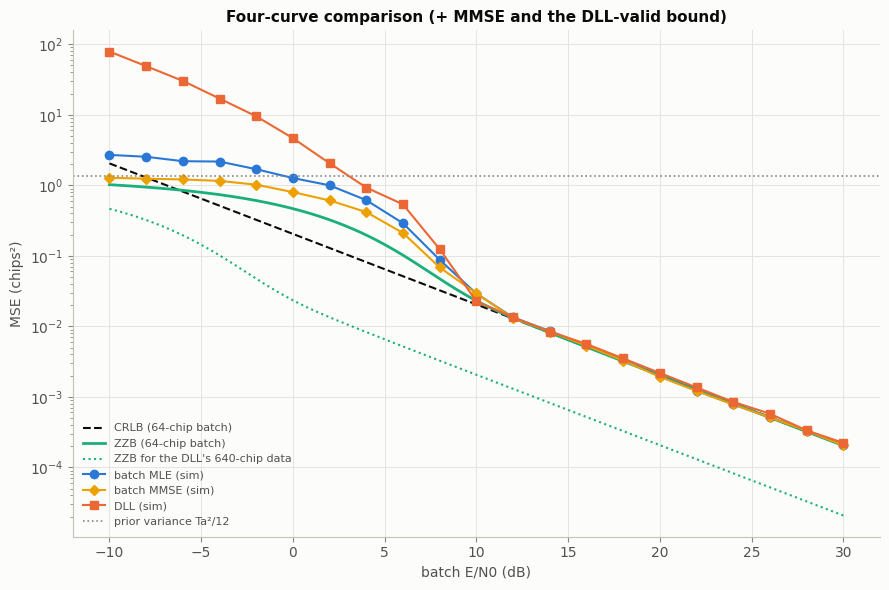

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.semilogy(xf, crf, color=COLORS["crlb"], ls="--", lw=1.5, label="CRLB (64-chip batch)")
ax.semilogy(xf, zzf, color=COLORS["zzb"], lw=2, label="ZZB (64-chip batch)")
ax.semilogy(xf, zzf_dll, color=COLORS["zzb"], ls=":", lw=1.5, label="ZZB for the DLL's 640-chip data")
ax.semilogy(snr_db, mse_ml, "o-", color=COLORS["mle"], lw=1.5, label="batch MLE (sim)")
ax.semilogy(snr_db, mse_mm, "D-", color=COLORS["mmse"], lw=1.5, ms=5, label="batch MMSE (sim)")
ax.semilogy(snr_db, mse_dl, "s-", color=COLORS["dll"], lw=1.5, label="DLL (sim)")
ax.axhline(prior_variance(cfg), color=COLORS["prior"], ls=":", lw=1.2, label="prior variance Ta²/12")
ax.set_xlabel("batch E/N0 (dB)"); ax.set_ylabel("MSE (chips²)")
ax.set_ylim(zzf_dll.min() * 0.5, mse_dl.max() * 2)
ax.set_title("Four-curve comparison (+ MMSE and the DLL-valid bound)")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG + "s5_four_curves.png")

**What the plot shows.**
* Above ≈ 12 dB all estimators sit on the 64-chip CRLB (the DLL slightly above, by design — B).
* The **MMSE is always at or below the MLE**, and at low SNR it flattens at the prior variance exactly as the ZZB
  predicts (1.28 vs ZZB 1.02 at −10 dB, where the MLE is at 2.70). **In the threshold region, however, it is only
  ≈ 0.6 dB better than the MLE** in this coarse run (section E; the precise value from notebook 06 is
  0.85 dB, CI 0.25–1.24). So at low SNR the ZZB–MLE gap is mostly the MLE being suboptimal, but
  around the threshold most of the gap is the bound itself being optimistic (it is built from *pairwise* tests, while
  any estimator must beat *all* competing delays at once).
* Below threshold the **DLL gets far worse** than both batch estimators — and it stays above the ZZB for its own
  640-chip data, the only bound that applies to it.

**How to explain it.** *"At high SNR every method is limited by noise on the correlation peak — the CRLB. Below
threshold the batch methods are limited by confusing peaks, which the ZZB captures, and the DLL fails for an extra
reason: it can lose lock."*

## D. Why the DLL fails differently (Sprint 6)

**What.** Every DLL trial with a gross final error (|e| > 0.5 chip) is assigned to exactly one cause:
1. **acquired outside the pull-in range** (initial error > 1.8 chips): tracking never had a chance — the same
   "wrong peak" mechanism as the MLE, decided by the coarse acquisition;
2. **acquired inside, then lost lock**: noise pushed the error out of the S-curve's restoring region during tracking.

**Why.** It turns "the DLL is worse" into a mechanism. The second cause does not exist for a batch estimator, and
it gets worse the longer the loop runs (the right panel), so below threshold the DLL has no single MSE value.

0 dB: gross 0.538 = acquisition 0.116 + lost lock 0.422
4 dB: gross 0.187 = acquisition 0.045 + lost lock 0.142
8 dB: gross 0.016 = acquisition 0.004 + lost lock 0.012


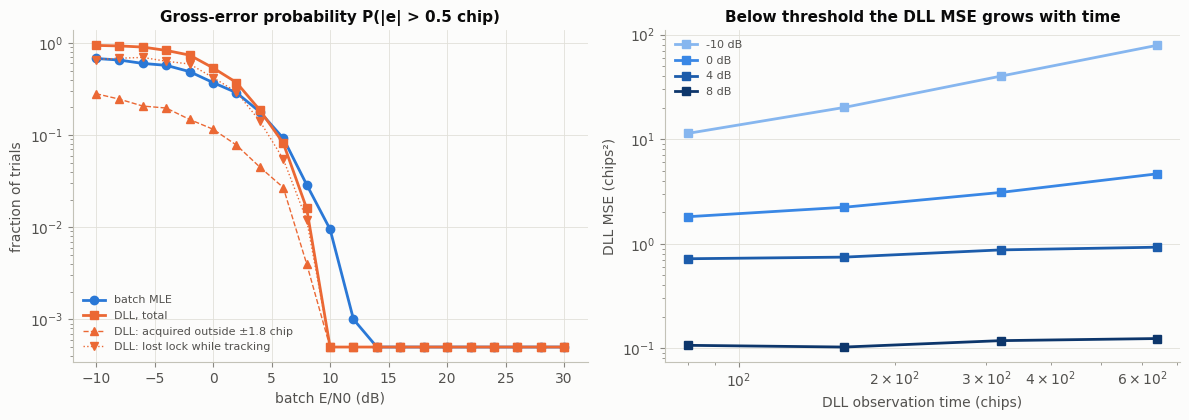

In [7]:
pull_in = dll.pull_in_range(rng)
gross = np.abs(err_dl) > 0.5
acq_out = np.abs(err_acq) > pull_in
p_tot, p_acq, p_lock = gross.mean(1), (gross & acq_out).mean(1), (gross & ~acq_out).mean(1)
floor = 0.5 / Nd

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].semilogy(snr_db, np.maximum(np.mean(np.abs(err_ml) > 0.5, 1), floor), "o-", color=COLORS["mle"], label="batch MLE")
ax[0].semilogy(snr_db, np.maximum(p_tot, floor), "s-", color=COLORS["dll"], label="DLL, total")
ax[0].semilogy(snr_db, np.maximum(p_acq, floor), "^--", color=COLORS["dll"], lw=1, label=f"DLL: acquired outside ±{pull_in:.1f} chip")
ax[0].semilogy(snr_db, np.maximum(p_lock, floor), "v:", color=COLORS["dll"], lw=1, label="DLL: lost lock while tracking")
ax[0].set_xlabel("batch E/N0 (dB)"); ax[0].set_ylabel("fraction of trials")
ax[0].set_title("Gross-error probability P(|e| > 0.5 chip)"); ax[0].legend(loc="lower left", fontsize=8)

tch = np.array(checkpoints) * cfg.dll_block_chips
for color, d in zip(["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"], (-10, 0, 4, 8)):
    i = int(np.where(snr_db == d)[0][0])
    ax[1].loglog(tch, np.mean(err_cp[i] ** 2, 1), "s-", color=color, label=f"{d} dB")
ax[1].set_xlabel("DLL observation time (chips)"); ax[1].set_ylabel("DLL MSE (chips²)")
ax[1].set_title("Below threshold the DLL MSE grows with time"); ax[1].legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG + "s6_dll_failure_mechanisms.png")
for d in (0, 4, 8):
    i = int(np.where(snr_db == d)[0][0])
    print(f"{d} dB: gross {p_tot[i]:.3f} = acquisition {p_acq[i]:.3f} + lost lock {p_lock[i]:.3f}")

## E. Locating the threshold SNR — with error bars (Sprint 6)

**What.** Two definitions, both fixed *before* looking at results:
* **MSE criterion:** the highest SNR at which MSE/CRLB first exceeds 2 (3 dB);
* **gross-error criterion:** the highest SNR at which P(|e| > 0.5 chip) first exceeds 1 %.

Uncertainty comes from a **bootstrap**: resample the trials at each SNR, recompute the threshold, repeat 200 times,
take the 2.5–97.5 % range.

**Why.** Near the threshold the MSE is dominated by *rare* gross errors, so a single unlucky trial can move an
MSE-based threshold by a dB or more. Without error bars, "the DLL is 1 dB worse than the MLE" is not a defensible
statement. The gross-error criterion is less sensitive to single outliers.

*Note:* this notebook uses the 2-dB grid and 1000–2000 trials from above, so the intervals are wide. The independent
high-precision runs (40,000 trials, 0.5-dB grid) are summarised after the table.

In [8]:
def crossing(x, y, level):
    """Highest x at which y (larger at low SNR) first exceeds `level`, scanning down from high SNR."""
    for i in range(len(x) - 1, 0, -1):
        if y[i] <= level < y[i - 1]:
            f = (np.log(level) - np.log(y[i])) / (np.log(y[i - 1]) - np.log(y[i]))
            return x[i] + f * (x[i - 1] - x[i])
    return np.nan

def thresholds(err):
    mse_ratio = np.mean(err ** 2, 1) / cr
    p_gross = np.maximum(np.mean(np.abs(err) > 0.5, 1), 1e-12)
    return crossing(snr_db, mse_ratio, 2.0), crossing(snr_db, p_gross, 0.01)

def bootstrap(err, n_boot=200):
    g = np.random.default_rng(0)
    b = np.array([thresholds(np.take_along_axis(err, g.integers(0, err.shape[1], err.shape), 1))
                  for _ in range(n_boot)])
    est = thresholds(err)
    return [(est[k], *np.nanpercentile(b[:, k], [2.5, 97.5])) for k in range(2)]

print("                MSE > 2 x CRLB             P(gross) > 1 %")
for name, e in (("batch MLE ", err_ml), ("batch MMSE", err_mm), ("DLL       ", err_dl)):
    (m, ml, mh), (g_, gl, gh) = bootstrap(e)
    print(f"{name}   {m:5.1f} dB [{ml:4.1f}, {mh:4.1f}]     {g_:5.1f} dB [{gl:4.1f}, {gh:4.1f}]")
print(f"ZZB          {crossing(xf, zzf / crf, 2.0):5.1f} dB")

                MSE > 2 x CRLB             P(gross) > 1 %
batch MLE      8.9 dB [ 8.2,  9.4]       9.9 dB [ 9.2, 10.3]


batch MMSE     8.3 dB [ 7.6,  9.1]      10.1 dB [ 9.5, 10.3]
DLL            9.0 dB [ 8.0,  9.3]       8.0 dB [ 7.9,  8.1]
ZZB            5.9 dB


**High-precision results — see notebook 06** (20,000 trials per point for MLE/MMSE, 4000 for the DLL, 0.5-dB grid,
current code), consistent with the independent October validation (40,000 trials: MLE 9.4 dB [9.3, 9.6]):

| Quantity (pilot 2026, MSE criterion) | Result |
|---|---|
| batch-MLE threshold | **9.52 dB, 95 % CI [9.00, 9.66]** |
| batch-MMSE threshold | 8.54 dB [8.35, 9.07]; MLE − MMSE = 0.85 dB [0.25, 1.24] |
| ZZB threshold | 5.95 dB |
| MLE − ZZB gap over 5 random pilots | 2.7 – 5.4 dB (mean 3.5; depends on the pilot) |
| DLL − MLE, MSE criterion | −0.12 dB [−0.87, 0.59] — **not significant** |
| DLL − MLE, gross-error criterion | −0.68 dB [−0.99, −0.40] — DLL **more robust** near threshold (640 chips of data) |
| gap vs prior width (Ta = 16) | earlier validation only (1000–5000 trials): shrinks on average, not for every pilot |

**How to explain it.** *"The threshold is where rare large errors start to dominate. Because they are rare, you need
many trials and confidence intervals to locate it; with them, the MLE's threshold is about 9.5 dB, roughly 3.5 dB
above where the ZZB bends. The DLL's MSE threshold is not significantly different from the MLE's, but it makes fewer
gross errors near threshold because it observes ten times more data."*

## F. Independent validation and the literature

The whole pipeline was checked by three **independent** reviews (details: `archive/docs_v1/validation_report.md`):

| Check | Outcome |
|---|---|
| Literature: ZZB form, $P_{\min}$, limits, CRLB, DLL loop formulas | all correct (Bell et al. 1997; Kay §3.11; Stephens & Thomas 1995) |
| Re-implementation from scratch (CRLB, ZZB, MLE) | agree to 0.02 %, 0.12 %, and within Monte Carlo error |
| Adversarial code audit | no estimator uses the true delay; DLL calibration independent of timing phase |
| Problems found **and fixed** | unfair DLL/ZZB comparison, thresholds without error bars, wrong pull-in claim (0.75 → 1.8 chips), DLL window artefact, several over-claims in the text |

**Literature position (what is already known):** comparisons of the ZZB with correlator/MLE performance for delay
estimation exist (Ianniello, Weinstein & Weiss 1983; Mallat et al. 2014; Xu, Baggeroer & Richmond 2004), and a ZZB for
pilots with unknown data exists for OFDM (Graff & Humphreys 2024). **What appears open:** a bound that captures the
DLL's *loss-of-lock* threshold — loss of lock is analysed with mean-time-to-lose-lock theory (Holmes & Biederman 1978),
but no recursive Bayesian bound (ZZB/WWB) for code-tracking loss of lock was found. Section D is the experimental
starting point for that direction.

## What to say about this notebook
> "Beyond Sprint 4 we already have the Sprint-5 four-curve comparison and the Sprint-6 threshold analysis, validated
> independently. They show that around the threshold the ZZB is optimistic by roughly 2–3 dB even for the best
> (MMSE) estimator, and that the DLL has an extra failure mode, loss of lock, that no batch bound describes — which is
> our candidate research direction."